### 多项式回归升维实战（一）

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

创建数据

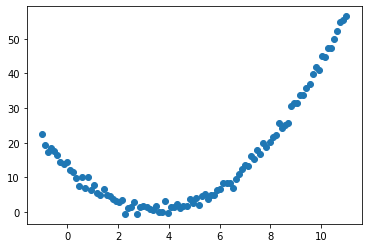

In [3]:
X = np.linspace(-1,11,num = 100)
y = (X - 5)**2 + 3 * X -12 + np.random.randn(100)
X = X.reshape(-1,1) # 数据就是二维数据，机器学习，算法要求

plt.scatter(X,y)

使用线性回归进行预测(一维，规律，自然无法获取)

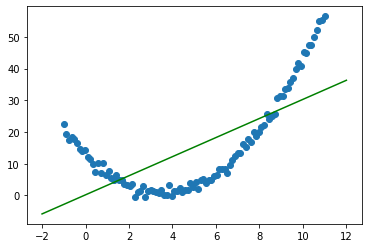

In [6]:
model = LinearRegression()
model.fit(X,y) # 训练

X_test = np.linspace(-2,12,300).reshape(-1,1)

# 算法预测，数据范围-2 到 12,等差数列300份
model.fit(X,y)

y_pred = model.predict(X_test)

plt.scatter(X,y)
plt.plot(X_test,y_pred,color = 'green') # 预测数据

升维(二维，直线就可以拐弯~)

In [18]:
display(X[:5],X2[:5])

array([[-1.        ],
       [-0.87878788],
       [-0.75757576],
       [-0.63636364],
       [-0.51515152]])

array([[-1.        ,  1.        ],
       [-0.87878788,  0.77226814],
       [-0.75757576,  0.57392103],
       [-0.63636364,  0.40495868],
       [-0.51515152,  0.26538108]])

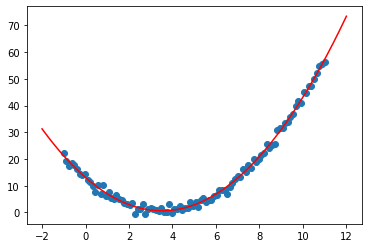

In [14]:
np.set_printoptions(suppress=True)

X2 = np.concatenate([X, X**2],axis = 1)
# 目标值，需要修改吗？
# 目标值，不需要处理

model2 = LinearRegression()
model2.fit(X2, y)

X_test2 = np.concatenate([X_test,X_test**2],axis = 1)
y_pred = model2.predict(X_test2)

# 可视化
plt.scatter(X,y)

# 算法预测结果，依然使用原数据（升维，是不是在一次幂的基础上，进行了平方）
plt.plot(X_test,y_pred,color = 'red')

In [15]:
model2.coef_

array([-7.09150933,  1.0100886 ])

In [16]:
model2.intercept_

13.06965456901894

### 多项式升维实战（二）

In [19]:
from sklearn.linear_model import LinearRegression
# PolynomialFeatures，多项式，升维
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
import numpy as np

$X^2 - 7X + 12$

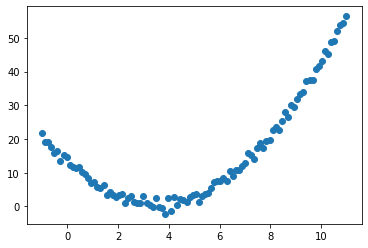

In [20]:
X = np.linspace(-1,11,num = 100)
y = (X - 5)**2 + 3 * X -12 + np.random.randn(100)
X = X.reshape(-1,1) # 数据就是二维数据，机器学习，算法要求

plt.scatter(X,y)

In [21]:
X_test = np.linspace(-2,12,300).reshape(-1,1)
X_test.shape

(300, 1)

In [27]:
poly = PolynomialFeatures(interaction_only=True) # 特征和特征之间进行相乘

A = [[3,2]]

poly.fit_transform(A) # (3**0 ,2**0),3**1,2**1, 2*3

array([[1., 3., 2., 6.]])

$3^12^1 = 6$

$3^12^0 = 3$

In [30]:
poly = PolynomialFeatures(degree=2,interaction_only=False) # 特征之间乘法，并且，自己和自己进行运算

A = [[3,2]]

poly.fit_transform(A) # 3**0,3**1,3**2

array([[1., 3., 2., 9., 6., 4.]])

In [41]:
poly = PolynomialFeatures(degree = 2)
X2 = poly.fit_transform(X)
X2.shape

X_test2 = poly.fit_transform(X_test)

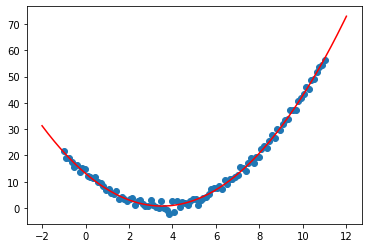

In [42]:
model = LinearRegression()

model.fit(X2,y)

y_pred = model.predict(X_test2)

plt.scatter(X,y)

plt.plot(X_test,y_pred,'red')

In [43]:
model.coef_

array([ 0.        , -7.06181936,  1.00385328])

### 天猫双十一线性拟合

In [86]:
from sklearn.linear_model import SGDRegressor,LinearRegression
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

array([[ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10],
       [11]])

array([   0.5 ,    9.36,   52.  ,  191.  ,  350.  ,  571.  ,  912.  ,
       1207.  , 1682.  , 2135.  , 2684.  ])

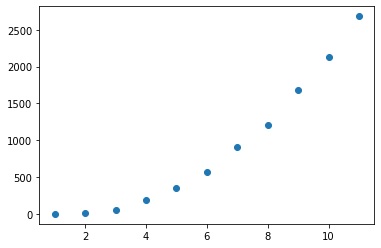

In [59]:
X = np.arange(2009, 2020).reshape(-1,1) - 2008 # 左闭右开，2020,2019

# 双十一销量（亿元） 2009 到2019
y = np.array([0.5,9.36,52,191,350,571,912,1207,1682,2135,2684])
display(X,y)
plt.scatter(X,y)

In [96]:
X_test = np.linspace(2009,2019,50).reshape(-1,1) - 2008 # 左闭右闭

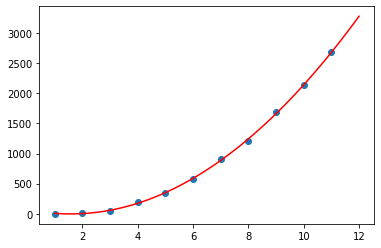

In [79]:
poly = PolynomialFeatures(degree = 2,interaction_only=False)
X_2 = poly.fit_transform(X)

# 线性回归，可以不使用归一化
model = LinearRegression(fit_intercept = False)
model.fit(X_2,y) # 训练时，数据升过维的

X_test2 = poly.fit_transform(X_test)
y_pred = model.predict(X_test2) # 预测时，数据必须：升维
plt.scatter(X,y)
plt.plot(X_test,y_pred,color = 'red')

In [81]:
X_2

array([[  1.,   1.,   1.],
       [  1.,   2.,   4.],
       [  1.,   3.,   9.],
       [  1.,   4.,  16.],
       [  1.,   5.,  25.],
       [  1.,   6.,  36.],
       [  1.,   7.,  49.],
       [  1.,   8.,  64.],
       [  1.,   9.,  81.],
       [  1.,  10., 100.],
       [  1.,  11., 121.]])

In [80]:
model.coef_

array([ 72.66460606, -95.53875524,  30.23736597])

$f(x) = 30.23 x^2 - 95.52 x + 72.66$

In [83]:
30.23 * 12**2 - 95.52 * 12 + 72.66

3279.54

In [99]:
X_2

array([[   1.,    1.,    1.,    1.],
       [   1.,    2.,    4.,    8.],
       [   1.,    3.,    9.,   27.],
       [   1.,    4.,   16.,   64.],
       [   1.,    5.,   25.,  125.],
       [   1.,    6.,   36.,  216.],
       [   1.,    7.,   49.,  343.],
       [   1.,    8.,   64.,  512.],
       [   1.,    9.,   81.,  729.],
       [   1.,   10.,  100., 1000.],
       [   1.,   11.,  121., 1331.]])

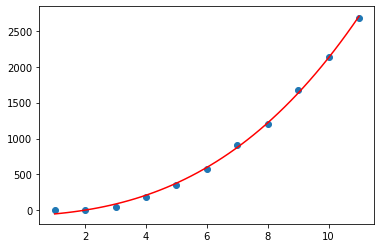

In [98]:
poly = PolynomialFeatures(degree = 3,interaction_only=False)
X_2 = poly.fit_transform(X)

stardard = StandardScaler() # 标准，基准
X_2_norm = stardard.fit_transform(X_2)

model = SGDRegressor(eta0=0.5,max_iter=10000)
model.fit(X_2_norm,y) # 训练时，数据升过维的

X_test2 = poly.fit_transform(X_test)
X_test2_norm = stardard.transform(X_test2)
y_pred = model.predict(X_test2_norm) # 预测时，数据必须：升维


plt.scatter(X,y)
plt.plot(X_test,y_pred,color = 'red')

### 中国人寿保费预测

In [100]:
import pandas as pd

In [101]:
import seaborn as sns

In [102]:
data = pd.read_excel('./中国人寿.xlsx')
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<AxesSubplot:xlabel='charges', ylabel='Density'>

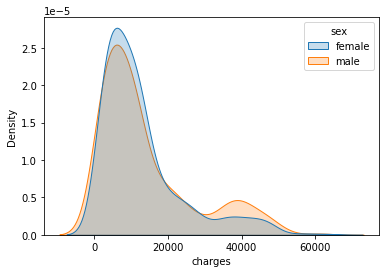

In [103]:
# 概率分布曲线
# 什么样特征是好特征：区别度大，明显
sns.kdeplot(data['charges'],shade = True,hue = data['sex'])

<AxesSubplot:xlabel='charges', ylabel='Density'>

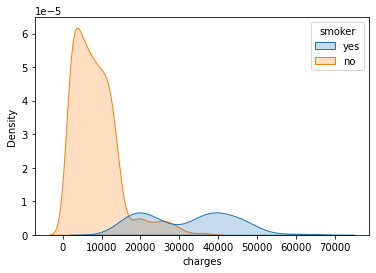

In [104]:
# 概率分布曲线
# 特征，好特征
sns.kdeplot(data['charges'],shade = True,hue = data['smoker'])

<AxesSubplot:xlabel='charges', ylabel='Density'>

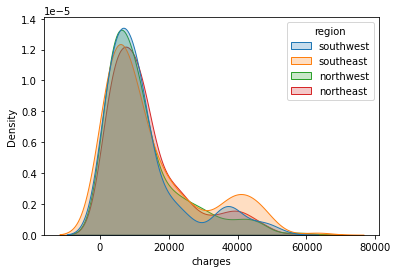

In [105]:
# 概率分布曲线
# 特征，区域，对保费，影响不明显，很好区分度
# 不重要，可有可无，删除
sns.kdeplot(data['charges'],shade = True,hue = data['region'])

<AxesSubplot:xlabel='charges', ylabel='Density'>

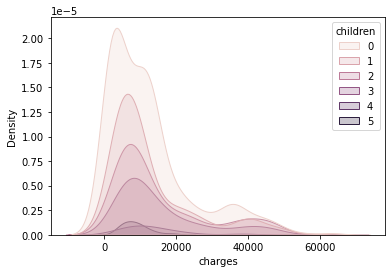

In [106]:
# 有一定区分度，建议特征留下
sns.kdeplot(data['charges'],shade = True,hue = data['children'])